# Milestone 3 - Exploratory Data Analysis
**Martik Farm Enterprises** | Ephantus Macharia | Data Science & Analytics capstone

This notebook explores the **cleaned** data (`data_clean/`, produced in Milestone 2) to answer the business questions in
`docs/problem_statement.md`: distributions, trends over time, seasonality, and differences across stores, counties, products and
customer segments. Every chart has a written observation, and the notebook ends with **the five findings that matter most**
(also saved to `docs/eda_findings.md`). Charts are saved to `figures/`.

> **Reading note.** The sales data is synthetic, calibrated on Martik's real price list and business facts (see `DATA_README.md`).
> Some patterns here (the Oct-Dec peak, credit-based payment, peak-season price rises on peppers, grapes, onions, tomatoes and oranges)
> came from the owner's knowledge and were built into the simulation, so the analysis confirms and **sizes** them. The
> sizes, the concentration and the segment differences are what a manager would act on. Observations describe this dataset, not the real business.

**Method notes:** revenue = `line_total_kes` (billed quantity x price after discounts and rejections). "Store" = the shop the product
is fulfilled from (potato products from Ruiru, everything else from the CBD shop; walk-in sales at the shop where they happened).
"County" = the customer's county.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mt
from IPython.display import Markdown, display

ROOT = Path("..").resolve(); FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)

# Colours: validated categorical slots 1-3 (blue, orange, aqua) plus neutral greys. Blue is the default, orange highlights.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GREY, INK, INK2, GRID, SURF = "#9c9b95", "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "font.size": 10, "axes.titlesize": 10.5,
                     "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.edgecolor": GREY,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK})

def tidy(ax, grid="y"):
    for s in ("top", "right"): ax.spines[s].set_visible(False)
    ax.tick_params(length=0, labelsize=9)
    if grid != "none": ax.grid(axis=grid, color=GRID, lw=0.8)
    ax.set_axisbelow(True)

def headline(fig, text, y=1.05):
    fig.suptitle(text, x=0.0, ha="left", y=y, fontsize=12.5, fontweight="bold", color=INK)

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight", facecolor=SURF); plt.show()

def md(*lines): display(Markdown("\n".join(lines)))

def hbar(ax, labels, values, fmt, colors=BLUE, pad=0.015):
    y = np.arange(len(labels))[::-1]
    ax.barh(y, values, color=colors, height=0.62)
    ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=9, color=INK)
    for yi, v in zip(y, values): ax.text(v + max(values) * pad, yi, fmt(v), va="center", fontsize=9)
    ax.set_xlim(0, max(values) * 1.22); tidy(ax, "x"); ax.set_xticks([])

# ---- load the cleaned tables
f = pd.read_csv(ROOT / "data_clean/sales_fact.csv", parse_dates=["order_date"], low_memory=False)
o = pd.read_csv(ROOT / "data_clean/orders.csv", parse_dates=["order_date", "payment_date", "invoice_due_date"])
prods = pd.read_csv(ROOT / "data_clean/products.csv")
plist = pd.read_csv(ROOT / "data_clean/price_list_monthly.csv")
cal = pd.read_csv(ROOT / "data_clean/calendar.csv", parse_dates=["date"])
weekly = pd.read_csv(ROOT / "data_clean/weekly_sales.csv", parse_dates=["week_start"])
pop = pd.read_csv(ROOT / "data/public/kenya_county_population_2019.csv")   # public source: KNBS 2019 census

TOTAL = f["line_total_kes"].sum()
f["year"], f["month"] = f.order_date.dt.year, f.order_date.dt.month
acc = o[o.is_account == 1]
N = {}   # every number quoted in the findings is stored here, so text and charts cannot disagree
print(f"{f.order_date.min():%d %b %Y} to {f.order_date.max():%d %b %Y} | {o.shape[0]:,} orders | {len(f):,} order lines | "
      f"{f.customer_id.nunique()} customers | {f.product_id.nunique()} products | revenue KES {TOTAL/1e6:,.1f}M")

01 Oct 2024 to 30 Sep 2026 | 20,852 orders | 127,354 order lines | 72 customers | 71 products | revenue KES 75.9M


## 1. Distributions: what a typical order looks like

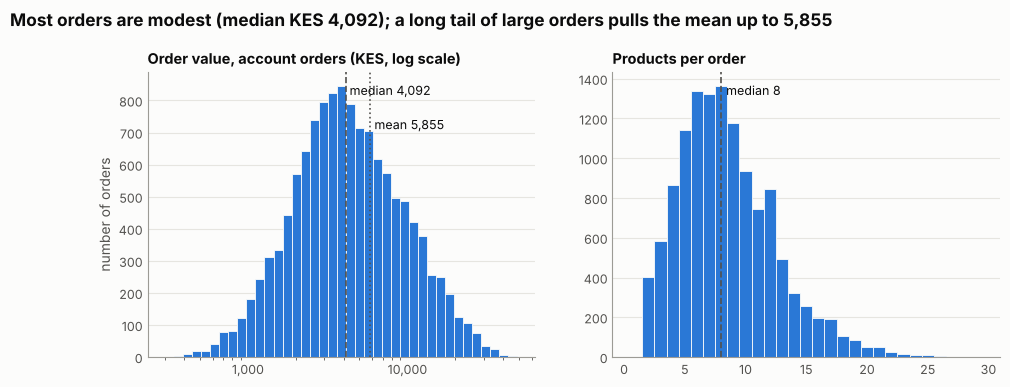

- **Skewed:** half of account orders are below KES 4,092, but the top 10% exceed KES 12,367 and the largest is KES 48,904. Use the median, not the mean, for a 'typical' order.
- A typical order carries **8 products**, so small baskets of many items rather than a few big ones.

In [2]:
v, ln = acc["order_total_kes"], acc["n_lines"]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.7))
ax[0].hist(v, bins=np.logspace(np.log10(v.min()), np.log10(v.max()), 40), color=BLUE, edgecolor=SURF, lw=0.6)
ax[0].set_xscale("log"); ax[0].xaxis.set_major_formatter(mt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
for val, name, ls, yy in [(v.median(), "median", "--", 0.92), (v.mean(), "mean", ":", 0.80)]:
    ax[0].axvline(val, color=INK2, lw=1.2, ls=ls)
    ax[0].text(val * 1.06, yy, f"{name} {val:,.0f}", transform=ax[0].get_xaxis_transform(), fontsize=9)
ax[0].set_title("Order value, account orders (KES, log scale)"); ax[0].set_ylabel("number of orders"); tidy(ax[0])
ax[1].hist(ln, bins=np.arange(0.5, ln.max() + 1.5, 1), color=BLUE, edgecolor=SURF, lw=0.6)
ax[1].axvline(ln.median(), color=INK2, lw=1.2, ls="--")
ax[1].text(ln.median() + 0.4, 0.92, f"median {ln.median():.0f}", transform=ax[1].get_xaxis_transform(), fontsize=9)
ax[1].set_title("Products per order"); tidy(ax[1])
N.update(aov_med=v.median(), aov_mean=v.mean(), aov_p90=v.quantile(.9), aov_max=v.max(), lines_med=ln.median())
headline(fig, f"Most orders are modest (median KES {v.median():,.0f}); a long tail of large orders pulls the mean up to {v.mean():,.0f}")
save(fig, "01_distributions")
md(f"- **Skewed:** half of account orders are below KES {v.median():,.0f}, but the top 10% exceed KES {v.quantile(.9):,.0f} and the largest is KES {v.max():,.0f}. Use the median, not the mean, for a 'typical' order.",
   f"- A typical order carries **{ln.median():.0f} products**, so small baskets of many items rather than a few big ones.")

## 2. Trends over time

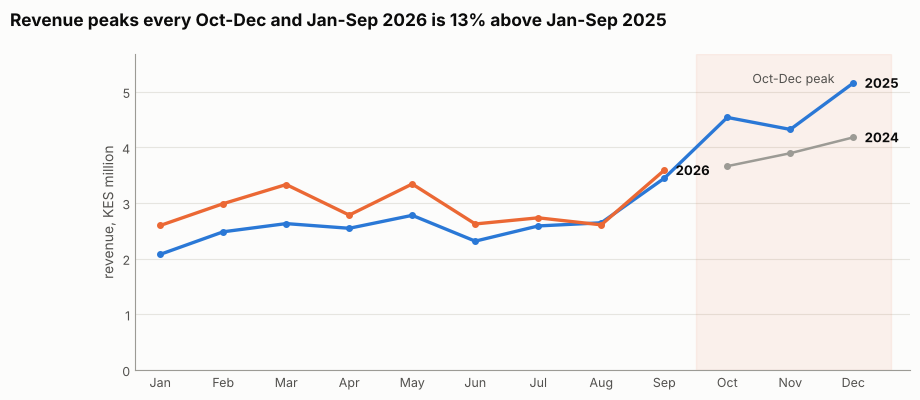

- **Growth:** Jan-Sep 2026 revenue was KES 26.6M vs 23.5M a year earlier (**+13.1%**), while units sold grew +10.9%. The gap is price (inflation and mix); active accounts rose from 60 to 63.
- **Q4 to Q4:** Oct-Dec 2025 brought KES 14.0M against 11.7M in Oct-Dec 2024 (+19%).
- December is the single biggest month in both years; January is the trough, with a clear dip again mid-year (Jun-Aug).

In [3]:
mo = f.groupby(["year", "month"])["line_total_kes"].sum().div(1e6).reset_index(name="rev")
fig, ax = plt.subplots(figsize=(10, 4.1))
ax.axvspan(9.5, 12.6, color=ORANGE, alpha=0.08)
for yr, col, lw in [(2024, GREY, 1.8), (2025, BLUE, 2.4), (2026, ORANGE, 2.4)]:
    d = mo[mo.year == yr]
    ax.plot(d.month, d.rev, color=col, lw=lw, marker="o", ms=4)
    ax.text(d.month.iloc[-1] + 0.18, d.rev.iloc[-1], str(yr), color=INK, va="center", fontsize=9.5, fontweight="bold")
ax.text(11.05, mo.rev.max() * 1.0, "Oct-Dec peak", ha="center", fontsize=9, color=INK2)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_xlim(0.6, 12.9); ax.set_ylim(0, mo.rev.max() * 1.1); ax.set_ylabel("revenue, KES million"); tidy(ax)
a = f[(f.order_date >= "2025-01-01") & (f.order_date <= "2025-09-30")]; b = f[(f.order_date >= "2026-01-01") & (f.order_date <= "2026-09-30")]
q4 = lambda y: f[(f.order_date >= f"{y}-10-01") & (f.order_date <= f"{y}-12-31")].line_total_kes.sum()
N.update(g_rev=(b.line_total_kes.sum() / a.line_total_kes.sum() - 1) * 100, g_qty=(b.billed_qty.sum() / a.billed_qty.sum() - 1) * 100,
         acc25=a.customer_id.nunique(), acc26=b.customer_id.nunique(), q424=q4(2024), q425=q4(2025),
         rev25=a.line_total_kes.sum(), rev26=b.line_total_kes.sum())
N["g_q4"] = (N["q425"] / N["q424"] - 1) * 100
headline(fig, f"Revenue peaks every Oct-Dec and Jan-Sep 2026 is {N['g_rev']:.0f}% above Jan-Sep 2025", y=0.99)
save(fig, "02_monthly_revenue_by_year")
md(f"- **Growth:** Jan-Sep 2026 revenue was KES {N['rev26']/1e6:.1f}M vs {N['rev25']/1e6:.1f}M a year earlier (**+{N['g_rev']:.1f}%**), while units sold grew +{N['g_qty']:.1f}%. The gap is price (inflation and mix); active accounts rose from {N['acc25']} to {N['acc26']}.",
   f"- **Q4 to Q4:** Oct-Dec 2025 brought KES {N['q425']/1e6:.1f}M against {N['q424']/1e6:.1f}M in Oct-Dec 2024 (+{N['g_q4']:.0f}%).",
   "- December is the single biggest month in both years; January is the trough, with a clear dip again mid-year (Jun-Aug).")

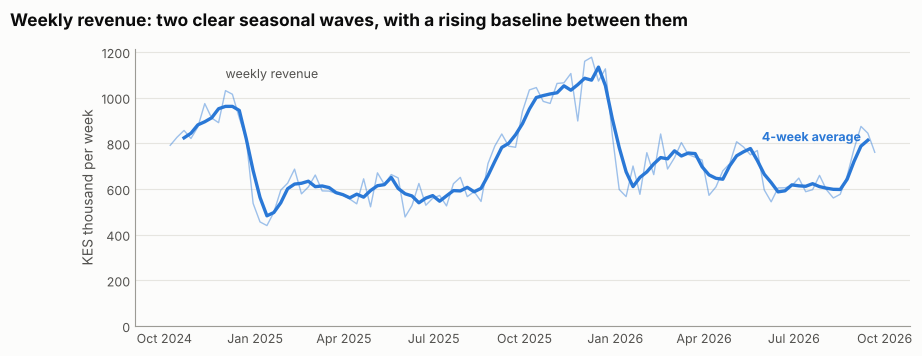

- Week to week the series is noisy (holidays, a few large orders), so judge trend from the 4-week average.
- The Oct-Dec build-up starts in **September** (weekly revenue is already above the summer level) and falls away sharply at the start of January.

In [4]:
w = weekly[weekly.category == "ALL"].sort_values("week_start").iloc[1:-1].copy()      # drop the two partial weeks at the ends
w["avg4"] = w.revenue_kes.rolling(4, center=True).mean()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(w.week_start, w.revenue_kes / 1e3, color=BLUE, lw=1, alpha=0.45)
ax.plot(w.week_start, w.avg4 / 1e3, color=BLUE, lw=2.4)
ax.text(w.week_start.iloc[-3], w.avg4.iloc[-3] / 1e3 + 22, "4-week average", color=BLUE, fontsize=9, fontweight="bold", ha="right")
ax.text(w.week_start.iloc[8], w.revenue_kes.iloc[8] / 1e3 + 55, "weekly revenue", color=INK2, fontsize=9)
ax.set_ylabel("KES thousand per week"); ax.set_ylim(0, None); tidy(ax)
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b %Y"))
headline(fig, "Weekly revenue: two clear seasonal waves, with a rising baseline between them", y=0.99)
save(fig, "03_weekly_revenue")
md("- Week to week the series is noisy (holidays, a few large orders), so judge trend from the 4-week average.",
   "- The Oct-Dec build-up starts in **September** (weekly revenue is already above the summer level) and falls away sharply at the start of January.")

## 3. Seasonality: how big is the peak, and what drives it?

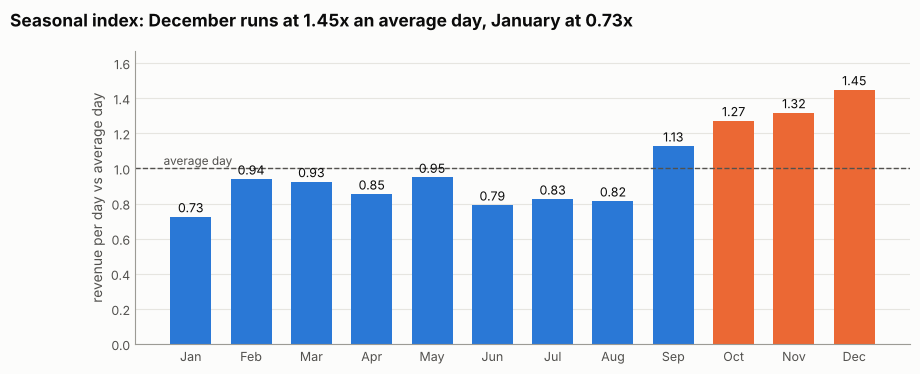

- **Peak:** Oct (orange) to Dec are the strongest months; **December is 2.0x January** per day.
- **Low season** matches what the owner described: January and mid-year (Jun-Aug) sit well below an average day.

In [5]:
dim = lambda y, m: pd.Period(f"{y}-{m:02d}").days_in_month
rm = f.groupby(["year", "month"])["line_total_kes"].sum().reset_index()
rm["rpd"] = rm.apply(lambda r: r.line_total_kes / dim(int(r.year), int(r.month)), axis=1)
si = rm.groupby("month").rpd.mean(); si = si / (TOTAL / len(cal))          # 1.00 = an average day
fig, ax = plt.subplots(figsize=(10, 3.8))
cols = [ORANGE if m >= 10 else BLUE for m in si.index]
ax.bar(si.index, si.values, color=cols, width=0.68)
for m, val in si.items(): ax.text(m, val + 0.025, f"{val:.2f}", ha="center", fontsize=9)
ax.axhline(1, color=INK2, lw=1, ls="--"); ax.text(0.55, 1.02, "average day", fontsize=8.5, color=INK2, ha="left")
ax.set_xticks(range(1, 13)); ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_ylabel("revenue per day vs average day"); ax.set_ylim(0, si.max() * 1.15); tidy(ax)
N.update(si_dec=si[12], si_jan=si[1], si_low=si[[1, 6, 7, 8]].mean())
headline(fig, f"Seasonal index: December runs at {si[12]:.2f}x an average day, January at {si[1]:.2f}x", y=0.99)
save(fig, "04_seasonal_index")
md(f"- **Peak:** Oct (orange) to Dec are the strongest months; **December is {si[12]/si[1]:.1f}x January** per day.",
   "- **Low season** matches what the owner described: January and mid-year (Jun-Aug) sit well below an average day.")

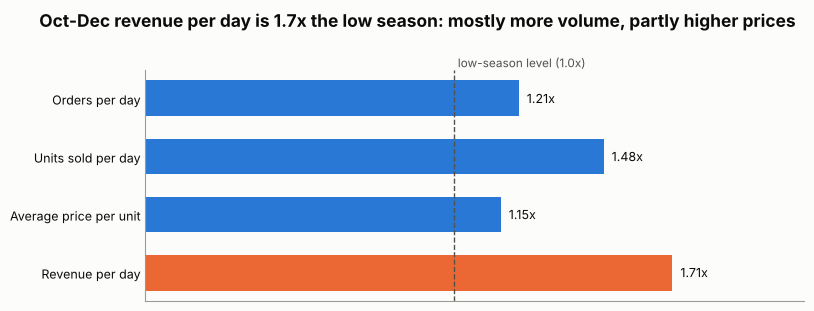

- Revenue per day is **1.71x** in the peak vs the low season (Jan, Jun-Aug). That is 1.21x as many orders per day, 1.48x the units sold per day and a 1.15x higher average price per unit.
- Roughly **74% of the uplift is volume and 26% price** (volume x price = revenue), so the peak is mainly a capacity and stock question, not just a pricing one.

In [6]:
season = lambda m: "peak" if m >= 10 else ("low" if m in (1, 6, 7, 8) else "other")
f["season"] = f.month.map(season)
days = {s: sum(dim(y, m) for y in (2024, 2025, 2026) for m in range(1, 13) if season(m) == s and
               f[(f.year == y) & (f.month == m)].shape[0] > 0) for s in ("peak", "low")}
g = f.groupby("season").agg(rev=("line_total_kes", "sum"), qty=("billed_qty", "sum"), orders=("order_id", "nunique"))
per_day = lambda s, col: g.loc[s, col] / days[s]
R = {"Orders per day": per_day("peak", "orders") / per_day("low", "orders"),
     "Units sold per day": per_day("peak", "qty") / per_day("low", "qty"),
     "Average price per unit": (g.loc["peak", "rev"] / g.loc["peak", "qty"]) / (g.loc["low", "rev"] / g.loc["low", "qty"]),
     "Revenue per day": per_day("peak", "rev") / per_day("low", "rev")}
fig, ax = plt.subplots(figsize=(8.5, 3.0))
hbar(ax, list(R), list(R.values()), lambda v: f"{v:.2f}x", colors=[BLUE, BLUE, BLUE, ORANGE])
ax.axvline(1, color=INK2, lw=1, ls="--"); ax.set_xlim(0, max(R.values()) * 1.25)
ax.text(1.0, 1.0, " low-season level (1.0x)", transform=ax.get_xaxis_transform(), fontsize=8.5, color=INK2, va="bottom")
N.update(peak_rev=R["Revenue per day"], peak_units=R["Units sold per day"], peak_price=R["Average price per unit"], peak_orders=R["Orders per day"])
N["vol_share"] = np.log(R["Units sold per day"]) / np.log(R["Revenue per day"]) * 100
headline(fig, f"Oct-Dec revenue per day is {R['Revenue per day']:.1f}x the low season: mostly more volume, partly higher prices", y=1.08)
save(fig, "05_peak_vs_low_decomposition")
md(f"- Revenue per day is **{R['Revenue per day']:.2f}x** in the peak vs the low season (Jan, Jun-Aug). That is {R['Orders per day']:.2f}x as many orders per day, "
   f"{R['Units sold per day']:.2f}x the units sold per day and a {R['Average price per unit']:.2f}x higher average price per unit.",
   f"- Roughly **{N['vol_share']:.0f}% of the uplift is volume and {100-N['vol_share']:.0f}% price** (volume x price = revenue), so the peak is mainly a capacity and stock question, not just a pricing one.")

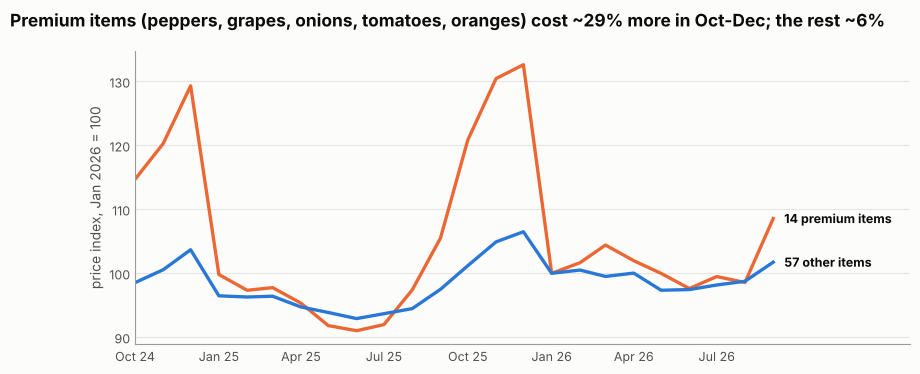

- Price index of a fixed basket, by group. The **14 premium products are 27% of revenue**, so their price swings matter.
- Peak-season prices run **29% above** low-season for premium items and 6% for the others; both drift up over time (inflation).

In [7]:
prem = set(prods.loc[prods.is_peak_season_premium == 1, "product_id"])
wq = f.groupby("product_id").billed_qty.sum()                          # fixed basket: total units sold of each product
plist["grp"] = np.where(plist.product_id.isin(prem), "premium", "other")
plist["wp"] = plist.list_price_kes * plist.product_id.map(wq)
idx = plist.groupby(["month", "grp"]).wp.sum().unstack()
idx = idx / idx.loc["2026-01"] * 100                                  # January 2026 = 100 for each group
pm = idx.index.str[5:].astype(int)
sea_ratio = {g_: idx.loc[[m_ in (10, 11, 12) for m_ in pm], g_].mean() / idx.loc[[m_ in (1, 6, 7, 8) for m_ in pm], g_].mean() for g_ in idx}
x = pd.to_datetime(idx.index + "-01")
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(x, idx["premium"], color=ORANGE, lw=2.4); ax.plot(x, idx["other"], color=BLUE, lw=2.4)
ax.text(x[-1] + pd.Timedelta(days=12), idx["premium"].iloc[-1], f"{len(prem)} premium items", color=INK, fontsize=9, fontweight="bold", va="center")
ax.text(x[-1] + pd.Timedelta(days=12), idx["other"].iloc[-1], f"{len(prods)-len(prem)} other items", color=INK, fontsize=9, fontweight="bold", va="center")
ax.set_xlim(x[0], x[-1] + pd.Timedelta(days=150)); ax.set_ylabel("price index, Jan 2026 = 100"); tidy(ax)
ax.set_xticks(pd.date_range(x[0], x[-1], freq="3MS"))
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%b %y"))
N.update(prem_up=(sea_ratio["premium"] - 1) * 100, other_up=(sea_ratio["other"] - 1) * 100, n_prem=len(prem),
         prem_share=f[f.product_id.isin(prem)].line_total_kes.sum() / TOTAL * 100)
headline(fig, f"Premium items (peppers, grapes, onions, tomatoes, oranges) cost ~{N['prem_up']:.0f}% more in Oct-Dec; the rest ~{N['other_up']:.0f}%", y=0.99)
save(fig, "06_price_seasonality")
md(f"- Price index of a fixed basket, by group. The **{len(prem)} premium products are {N['prem_share']:.0f}% of revenue**, so their price swings matter.",
   f"- Peak-season prices run **{N['prem_up']:.0f}% above** low-season for premium items and {N['other_up']:.0f}% for the others; both drift up over time (inflation).")

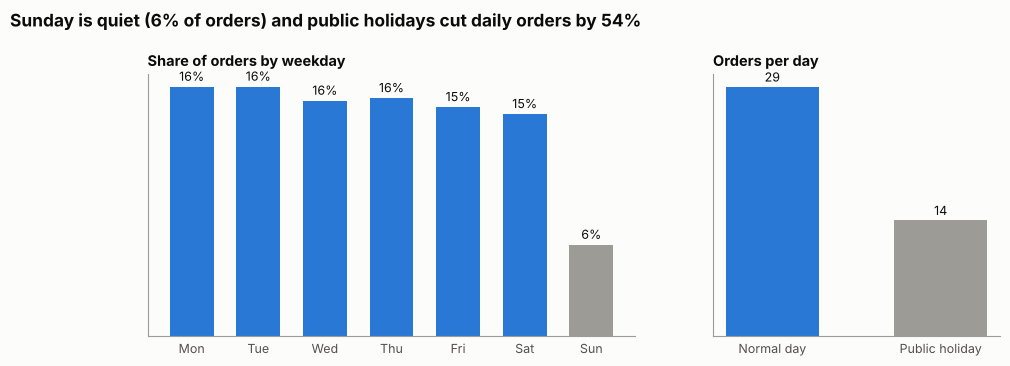

- Monday-Saturday carry almost equal order counts; **Sunday only 6%**.
- On public holidays the business takes **14 orders a day vs 29** on a normal day (-54%): plan staffing and deliveries around the calendar.

In [8]:
dow = o.groupby(o.order_date.dt.dayofweek).size(); dow = dow / dow.sum() * 100
dn = cal.set_index("date").loc[:, "is_public_holiday"]
hol = o.groupby("is_public_holiday").size() / dn.value_counts()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1.7, 1]})
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
ax[0].bar(names, dow.values, color=[GREY if n == "Sun" else BLUE for n in names], width=0.66)
for i, val in enumerate(dow.values): ax[0].text(i, val + 0.4, f"{val:.0f}%", ha="center", fontsize=9)
ax[0].set_title("Share of orders by weekday"); ax[0].set_yticks([]); tidy(ax[0], "none")
ax[1].bar(["Normal day", "Public holiday"], [hol[0], hol[1]], color=[BLUE, GREY], width=0.55)
for i, val in enumerate([hol[0], hol[1]]): ax[1].text(i, val + 0.6, f"{val:.0f}", ha="center", fontsize=9)
ax[1].set_title("Orders per day"); ax[1].set_yticks([]); tidy(ax[1], "none")
N.update(sun=dow.iloc[6], hol_drop=(1 - hol[1] / hol[0]) * 100, hol_o=hol[1], norm_o=hol[0])
headline(fig, f"Sunday is quiet ({dow.iloc[6]:.0f}% of orders) and public holidays cut daily orders by {N['hol_drop']:.0f}%", y=1.07)
save(fig, "07_weekday_and_holidays")
md(f"- Monday-Saturday carry almost equal order counts; **Sunday only {dow.iloc[6]:.0f}%**.",
   f"- On public holidays the business takes **{hol[1]:.0f} orders a day vs {hol[0]:.0f}** on a normal day (-{N['hol_drop']:.0f}%): plan staffing and deliveries around the calendar.")

## 4. Customer segments and concentration

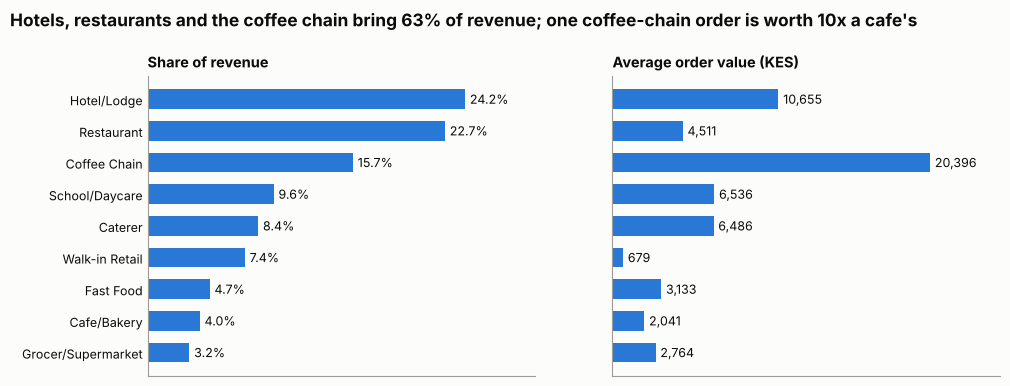

- **Hotels/lodges 24.2%, restaurants 22.7%, coffee chain 15.7%** (a single account) of revenue; walk-in retail is only 7.4%.
- Order size differs hugely: coffee chain KES 20,396, hotels 10,655, but cafes/bakeries only 2,041. Small segments are many orders for little money.

In [9]:
seg = f.groupby("segment").agg(rev=("line_total_kes", "sum")).join(o.groupby("segment").order_total_kes.mean().rename("aov")).sort_values("rev", ascending=False)
seg["share"] = seg.rev / TOTAL * 100
fig, ax = plt.subplots(1, 2, figsize=(11, 3.9), sharey=True)
hbar(ax[0], seg.index, seg.share.values, lambda v: f"{v:.1f}%"); ax[0].set_title("Share of revenue")
hbar(ax[1], seg.index, seg.aov.values, lambda v: f"{v:,.0f}"); ax[1].set_title("Average order value (KES)")
top3 = seg.loc[["Hotel/Lodge", "Restaurant", "Coffee Chain"], "share"].sum()
N.update(hotel=seg.loc["Hotel/Lodge", "share"], rest=seg.loc["Restaurant", "share"], coffee=seg.loc["Coffee Chain", "share"], top3=top3,
         hotel_aov=seg.loc["Hotel/Lodge", "aov"], coffee_aov=seg.loc["Coffee Chain", "aov"], walkin=seg.loc["Walk-in Retail", "share"],
         cafe_aov=seg.loc["Cafe/Bakery", "aov"])
headline(fig, f"Hotels, restaurants and the coffee chain bring {top3:.0f}% of revenue; one coffee-chain order is worth {seg.loc['Coffee Chain','aov']/seg.loc['Cafe/Bakery','aov']:.0f}x a cafe's")
save(fig, "08_segments")
md(f"- **Hotels/lodges {N['hotel']:.1f}%, restaurants {N['rest']:.1f}%, coffee chain {N['coffee']:.1f}%** (a single account) of revenue; walk-in retail is only {N['walkin']:.1f}%.",
   f"- Order size differs hugely: coffee chain KES {N['coffee_aov']:,.0f}, hotels {N['hotel_aov']:,.0f}, but cafes/bakeries only {N['cafe_aov']:,.0f}. Small segments are many orders for little money.")

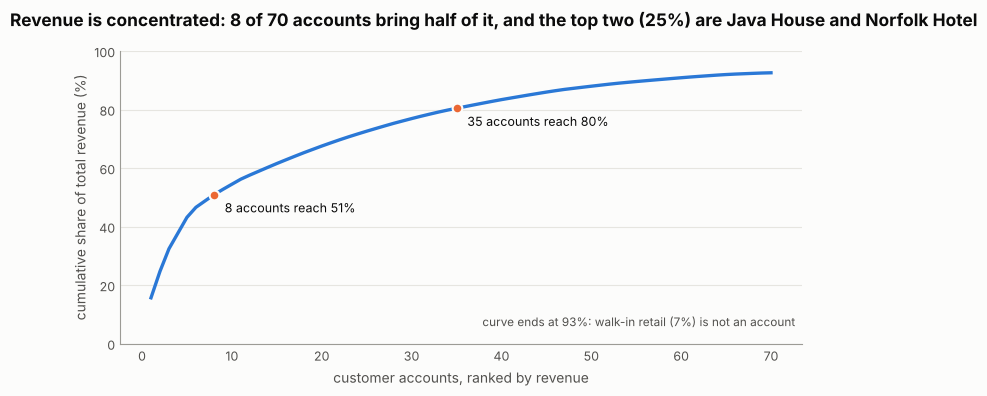

- **Top account:** Java House = 15.7% of revenue; next: Norfolk Hotel 9.1%, Hotel 033 7.7%.
- Top 2 = **24.7%**, top 5 = 43.2%, top 10 = 54.5% of all revenue. **8 accounts make half** the revenue and 35 of 70 make 80%.
- Losing one anchor account would hurt far more than losing several small ones, so account loss deserves the most attention in the churn model.

In [10]:
cn = f[f.is_account == 1].groupby("customer_id").line_total_kes.sum().sort_values(ascending=False)
cum = cn.cumsum() / TOTAL * 100
names = pd.read_csv(ROOT / "data_clean/customers.csv").set_index("customer_id").customer_name
k50, k80 = int((cum < 50).sum() + 1), int((cum < 80).sum() + 1)
fig, ax = plt.subplots(figsize=(8.8, 3.8))
ax.plot(range(1, len(cum) + 1), cum.values, color=BLUE, lw=2.4)
for k, lab in [(k50, "50%"), (k80, "80%")]:
    ax.plot([k], [cum.iloc[k - 1]], "o", color=ORANGE, ms=7, mec=SURF, mew=1.5)
    ax.text(k + 1.2, cum.iloc[k - 1] - 6, f"{k} accounts reach {cum.iloc[k-1]:.0f}%", fontsize=9)
ax.set_xlabel("customer accounts, ranked by revenue"); ax.set_ylabel("cumulative share of total revenue (%)"); ax.set_ylim(0, 100); tidy(ax)
ax.text(0.99, 0.06, f"curve ends at {cum.iloc[-1]:.0f}%: walk-in retail ({100-cum.iloc[-1]:.0f}%) is not an account", transform=ax.transAxes, ha="right", fontsize=8.5, color=INK2)
top = [(names[i], v / TOTAL * 100) for i, v in cn.head(3).items()]
N.update(top1=cn.iloc[0] / TOTAL * 100, top2=cn.iloc[:2].sum() / TOTAL * 100, top5=cn.iloc[:5].sum() / TOTAL * 100, top10=cn.iloc[:10].sum() / TOTAL * 100,
         k50=k50, k80=k80, n_acc=len(cn), top_names=top)
headline(fig, f"Revenue is concentrated: {k50} of {len(cn)} accounts bring half of it, and the top two ({N['top2']:.0f}%) are Java House and Norfolk Hotel", y=0.99)
save(fig, "09_customer_concentration")
md(f"- **Top account:** {top[0][0]} = {top[0][1]:.1f}% of revenue; next: {top[1][0]} {top[1][1]:.1f}%, {top[2][0]} {top[2][1]:.1f}%.",
   f"- Top 2 = **{N['top2']:.1f}%**, top 5 = {N['top5']:.1f}%, top 10 = {N['top10']:.1f}% of all revenue. **{k50} accounts make half** the revenue and {k80} of {len(cn)} make 80%.",
   "- Losing one anchor account would hurt far more than losing several small ones, so account loss deserves the most attention in the churn model.")

## 5. Stores and counties

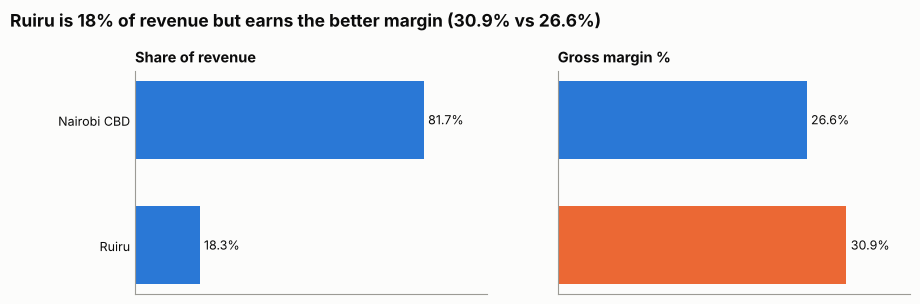

- **Nairobi CBD** fulfils 81.7% of revenue at a 26.6% gross margin; **Ruiru** (fries and potato products) 18.3% at **30.9%**.
- Each extra shilling of Ruiru's processed potato products earns more margin than the CBD's fresh produce, a case for growing the fries line.

In [11]:
st = f.groupby("store_name").agg(rev=("line_total_kes", "sum"), mar=("gross_margin_kes", "sum")); st["share"] = st.rev / TOTAL * 100; st["m"] = st.mar / st.rev * 100
st = st.sort_values("rev", ascending=False); lab = [s.replace("Martik Farm - ", "") for s in st.index]
fig, ax = plt.subplots(1, 2, figsize=(10, 2.9), sharey=True)
hbar(ax[0], lab, st.share.values, lambda v: f"{v:.1f}%", colors=BLUE); ax[0].set_title("Share of revenue")
hbar(ax[1], lab, st.m.values, lambda v: f"{v:.1f}%", colors=[BLUE, ORANGE]); ax[1].set_title("Gross margin %")
N.update(cbd_share=st.loc["Martik Farm - Nairobi CBD", "share"], ruiru_share=st.loc["Martik Farm - Ruiru", "share"],
         cbd_m=st.loc["Martik Farm - Nairobi CBD", "m"], ruiru_m=st.loc["Martik Farm - Ruiru", "m"])
headline(fig, f"Ruiru is {N['ruiru_share']:.0f}% of revenue but earns the better margin ({N['ruiru_m']:.1f}% vs {N['cbd_m']:.1f}%)", y=1.09)
save(fig, "10_stores")
md(f"- **Nairobi CBD** fulfils {N['cbd_share']:.1f}% of revenue at a {N['cbd_m']:.1f}% gross margin; **Ruiru** (fries and potato products) {N['ruiru_share']:.1f}% at **{N['ruiru_m']:.1f}%**.",
   "- Each extra shilling of Ruiru's processed potato products earns more margin than the CBD's fresh produce, a case for growing the fries line.")

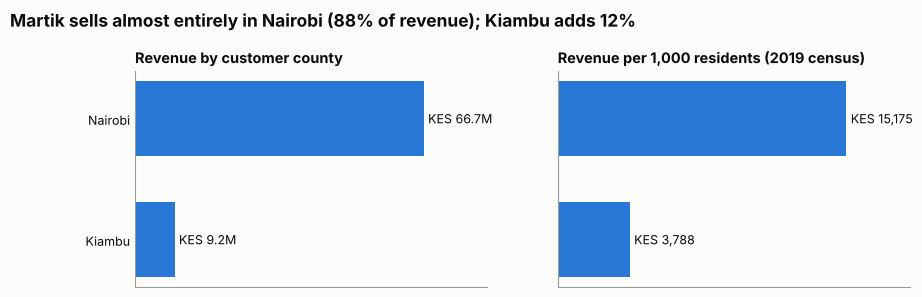

- Nairobi **87.9%**, Kiambu **12.1%**; no other county. Per 1,000 residents (public KNBS 2019 census data) Nairobi yields about KES 15,175 vs 3,788 in Kiambu.
- Only two counties are served, so the 47-county population table is context for expansion, not yet an explanation of differences.

In [12]:
ct = f.groupby("county").line_total_kes.sum().rename("rev").reset_index().merge(pop[["county", "population_2019"]], on="county")
ct["per1000"] = ct.rev / ct.population_2019 * 1000; ct = ct.sort_values("rev", ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(10, 2.8), sharey=True)
hbar(ax[0], ct.county, ct.rev.values / 1e6, lambda v: f"KES {v:.1f}M"); ax[0].set_title("Revenue by customer county")
hbar(ax[1], ct.county, ct.per1000.values, lambda v: f"KES {v:,.0f}"); ax[1].set_title("Revenue per 1,000 residents (2019 census)")
N.update(nbo_share=ct.set_index("county").rev["Nairobi"] / TOTAL * 100, kb_share=ct.set_index("county").rev["Kiambu"] / TOTAL * 100,
         nbo_pc=ct.set_index("county").per1000["Nairobi"], kb_pc=ct.set_index("county").per1000["Kiambu"])
headline(fig, f"Martik sells almost entirely in Nairobi ({N['nbo_share']:.0f}% of revenue); Kiambu adds {N['kb_share']:.0f}%", y=1.1)
save(fig, "11_counties")
md(f"- Nairobi **{N['nbo_share']:.1f}%**, Kiambu **{N['kb_share']:.1f}%**; no other county. Per 1,000 residents (public KNBS 2019 census data) Nairobi yields about KES {N['nbo_pc']:,.0f} vs {N['kb_pc']:,.0f} in Kiambu.",
   "- Only two counties are served, so the 47-county population table is context for expansion, not yet an explanation of differences.")

## 6. Products and categories

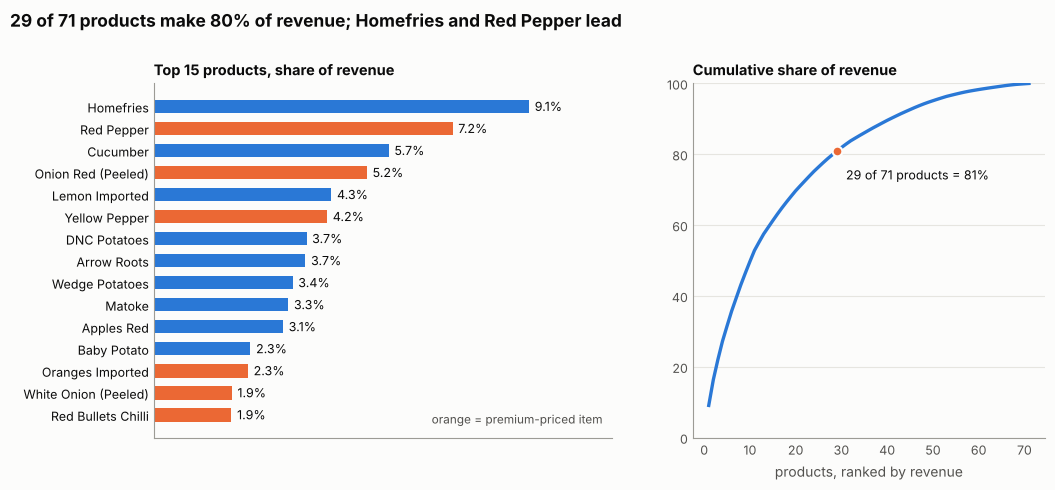

- **Homefries** (9.1%) and **Red Pepper** (7.2%) are the two biggest products; **29 of 71** products carry 80% of revenue.
- The remaining ~40 items are a long tail: worth stocking for service, but they do not drive the numbers.

In [13]:
p = f.groupby(["product_name", "category", "product_id"]).agg(rev=("line_total_kes", "sum"), mar=("gross_margin_kes", "sum")).reset_index().sort_values("rev", ascending=False)
p["share"] = p.rev / TOTAL * 100; p["m"] = p.mar / p.rev * 100; p["cum"] = p.share.cumsum(); p["premium"] = p.product_id.isin(prem)
k80p = int((p.cum < 80).sum() + 1)
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})
t15 = p.head(15)
hbar(ax[0], t15.product_name, t15.share.values, lambda v: f"{v:.1f}%", colors=[ORANGE if x else BLUE for x in t15.premium]); ax[0].set_title("Top 15 products, share of revenue")
ax[1].plot(range(1, len(p) + 1), p.cum.values, color=BLUE, lw=2.4); ax[1].plot([k80p], [p.cum.iloc[k80p - 1]], "o", color=ORANGE, ms=7, mec=SURF, mew=1.5)
ax[1].text(k80p + 2, p.cum.iloc[k80p - 1] - 8, f"{k80p} of {len(p)} products = {p.cum.iloc[k80p-1]:.0f}%", fontsize=9)
ax[1].set_title("Cumulative share of revenue"); ax[1].set_xlabel("products, ranked by revenue"); ax[1].set_ylim(0, 100); tidy(ax[1])
ax[0].text(0.98, 0.04, "orange = premium-priced item", transform=ax[0].transAxes, ha="right", fontsize=8.5, color=INK2)
N.update(k80p=k80p, n_prod=len(p), top1_name=p.iloc[0].product_name, top1_share=p.iloc[0].share, top2_name=p.iloc[1].product_name, top2_share=p.iloc[1].share)
headline(fig, f"{k80p} of {len(p)} products make 80% of revenue; {p.iloc[0].product_name} and {p.iloc[1].product_name} lead", y=1.04)
save(fig, "12_products_pareto")
md(f"- **{p.iloc[0].product_name}** ({p.iloc[0].share:.1f}%) and **{p.iloc[1].product_name}** ({p.iloc[1].share:.1f}%) are the two biggest products; **{k80p} of {len(p)}** products carry 80% of revenue.",
   "- The remaining ~40 items are a long tail: worth stocking for service, but they do not drive the numbers.")

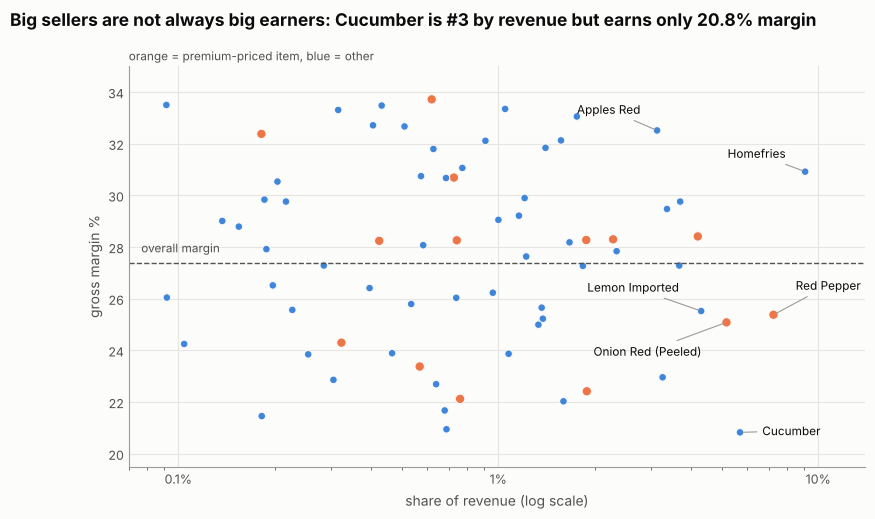

- Margins cluster between roughly 20% and 33% (overall **27.4%**). Homefries combine the top revenue with a 30.9% margin.
- **Cucumber** is among the top sellers (5.7% of revenue) with the lowest margin of the top 20 (20.8%): a candidate for repricing or a minimum order.

In [14]:
top20 = p.head(20)
fig, ax = plt.subplots(figsize=(9.5, 5.2))
ax.scatter(p.share, p.m, s=np.where(p.premium, 46, 30), c=[ORANGE if x else BLUE for x in p.premium], edgecolors=SURF, linewidths=0.8, alpha=0.9)
ax.set_xscale("log"); ax.xaxis.set_major_formatter(mt.FuncFormatter(lambda x, _: f"{x:g}%"))
ax.set_xlabel("share of revenue (log scale)"); ax.set_ylabel("gross margin %"); tidy(ax, "both")
ax.axhline(p.mar.sum() / p.rev.sum() * 100, color=INK2, lw=1, ls="--"); ax.text(ax.get_xlim()[0] * 1.05, p.mar.sum() / p.rev.sum() * 100 + 0.4, "overall margin", fontsize=8.5, color=INK2)
lowest = top20.sort_values("m").iloc[0]
ax.set_xlim(0.07, 14); ax.set_ylim(19.5, 35)
labels = {"Homefries": (-14, 10, "right"), "Red Pepper": (16, 18, "left"), "Onion Red (Peeled)": (-18, -24, "right"),
          "Lemon Imported": (-16, 14, "right"), "Apples Red": (-12, 12, "right")}
labels.setdefault(lowest.product_name, (16, -2, "left"))
for _, r in p.iterrows():
    if r.product_name in labels:
        dx, dy, ha = labels[r.product_name]
        ax.annotate(r.product_name, (r.share, r.m), xytext=(dx, dy), textcoords="offset points", fontsize=8.5, ha=ha,
                    arrowprops=dict(arrowstyle="-", color=GREY, lw=0.8))
ax.text(0.0, 1.015, "orange = premium-priced item, blue = other", transform=ax.transAxes, fontsize=8.5, color=INK2)
N.update(low_name=lowest.product_name, low_m=lowest.m, low_share=lowest.share, home_m=p[p.product_name == "Homefries"].m.iloc[0], overall_m=p.mar.sum() / p.rev.sum() * 100)
headline(fig, f"Big sellers are not always big earners: {lowest.product_name} is #3 by revenue but earns only {lowest.m:.1f}% margin", y=0.99)
save(fig, "13_revenue_vs_margin")
md(f"- Margins cluster between roughly 20% and 33% (overall **{N['overall_m']:.1f}%**). Homefries combine the top revenue with a {N['home_m']:.1f}% margin.",
   f"- **{lowest.product_name}** is among the top sellers ({lowest.share:.1f}% of revenue) with the lowest margin of the top 20 ({lowest.m:.1f}%): a candidate for repricing or a minimum order.")

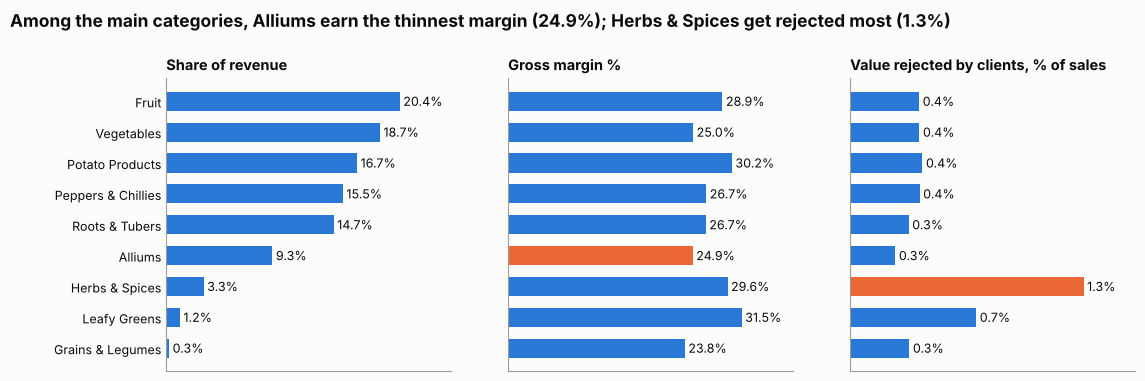

- **Fruit** is the largest category (20.4% of revenue); among the main categories (5%+ of revenue) margins run from **24.9% (Alliums)** to **30.2% (Potato Products)**.
- Clients reject only 0.4% of sales value overall, but **Herbs & Spices reach 1.3%** (short shelf life).

In [15]:
cat = f.groupby("category").agg(rev=("line_total_kes", "sum"), mar=("gross_margin_kes", "sum"), rej=("rejected_value_kes", "sum"), gross=("gross_revenue_kes", "sum"))
cat["share"] = cat.rev / TOTAL * 100; cat["m"] = cat.mar / cat.rev * 100; cat["rejp"] = cat.rej / cat.gross * 100; cat = cat.sort_values("rev", ascending=False)
fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.8), sharey=True)
hbar(ax[0], cat.index, cat.share.values, lambda v: f"{v:.1f}%"); ax[0].set_title("Share of revenue")
big = cat[cat.share >= 5]; worst_big, best_big = big.m.idxmin(), big.m.idxmax()      # judged among categories with >= 5% of revenue
hbar(ax[1], cat.index, cat.m.values, lambda v: f"{v:.1f}%", colors=[ORANGE if i == worst_big else BLUE for i in cat.index]); ax[1].set_title("Gross margin %")
hbar(ax[2], cat.index, cat.rejp.values, lambda v: f"{v:.1f}%", colors=[ORANGE if i == cat.rejp.idxmax() else BLUE for i in cat.index]); ax[2].set_title("Value rejected by clients, % of sales")
N.update(cat_top=cat.index[0], cat_top_share=cat.share.iloc[0], best_cat=best_big, best_m=big.m.max(), worst_cat=worst_big, worst_m=big.m.min(),
         rej_cat=cat.rejp.idxmax(), rej_v=cat.rejp.max(), rej_all=f.rejected_value_kes.sum() / f.gross_revenue_kes.sum() * 100)
headline(fig, f"Among the main categories, {worst_big} earn the thinnest margin ({big.m.min():.1f}%); {cat.rejp.idxmax()} get rejected most ({cat.rejp.max():.1f}%)", y=1.06)
save(fig, "14_categories")
md(f"- **{cat.index[0]}** is the largest category ({cat.share.iloc[0]:.1f}% of revenue); among the main categories (5%+ of revenue) margins run from **{big.m.min():.1f}% ({worst_big})** to **{big.m.max():.1f}% ({best_big})**.",
   f"- Clients reject only {N['rej_all']:.1f}% of sales value overall, but **{cat.rejp.idxmax()} reach {cat.rejp.max():.1f}%** (short shelf life).")

## 7. Credit: who pays late, and how much is outstanding?

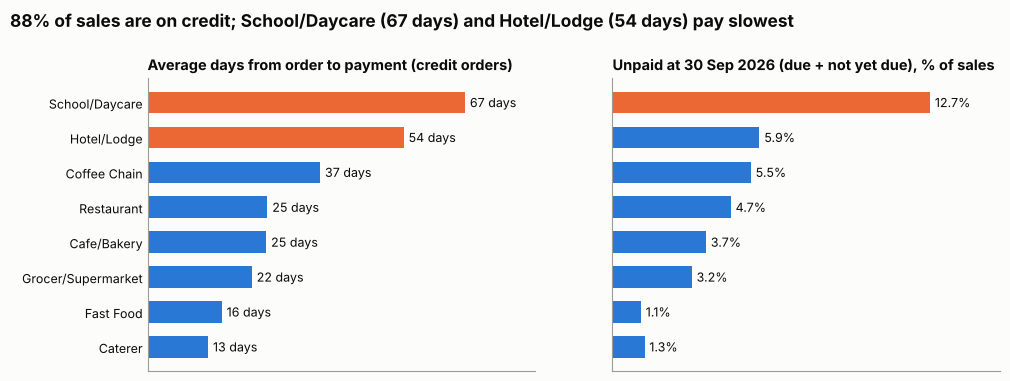

- **88% of revenue is sold on credit**; the value-weighted average time to pay is **39 days**.
- Slowest: **School/Daycare 67 days**, **Hotel/Lodge 54 days**; fastest: Caterer 13 days.
- At 30 Sep 2026 **KES 3.95M** was unpaid (of which KES 0.85M already past due) and KES 56K written off. Relative to its sales, **School/Daycare** has most unpaid (12.7%).
- Part of that is simply long terms (more invoices not yet due): only 3.1% of School/Daycare sales are actually past due.
- Largest unpaid balances: Java House KES 657K, Norfolk Hotel KES 570K, Riara School KES 335K.

In [16]:
paid = acc[(acc.payment_status == "Paid") & (acc.is_credit == 1)]
dt = paid.groupby("segment").days_to_pay.mean().sort_values(ascending=False)
sev = acc.groupby("segment").order_total_kes.sum()
out = o[o.payment_status.isin(["Open", "Overdue"]) & (o.is_account == 1)].groupby("segment").order_total_kes.sum()
oo = (out / sev * 100).reindex(dt.index).fillna(0)
credit_share = o[o.is_credit == 1].order_total_kes.sum() / o.order_total_kes.sum() * 100
wavg = np.average(paid.days_to_pay, weights=paid.order_total_kes)
open_all = o[o.payment_status.isin(["Open", "Overdue"])].order_total_kes.sum(); overdue = o[o.payment_status == "Overdue"].order_total_kes.sum()
wo = o[o.payment_status == "Written Off"].order_total_kes.sum()
by_acct = o[o.payment_status.isin(["Open", "Overdue"]) & (o.is_account == 1)].groupby("customer_id").order_total_kes.sum().sort_values(ascending=False)
ovr = (o[(o.payment_status == "Overdue") & (o.is_account == 1)].groupby("segment").order_total_kes.sum() / sev * 100).reindex(dt.index).fillna(0)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
hbar(ax[0], dt.index, dt.values, lambda v: f"{v:.0f} days", colors=[ORANGE if i < 2 else BLUE for i in range(len(dt))]); ax[0].set_title("Average days from order to payment (credit orders)")
hbar(ax[1], oo.index, oo.values, lambda v: f"{v:.1f}%", colors=[ORANGE if v == oo.max() else BLUE for v in oo.values]); ax[1].set_title("Unpaid at 30 Sep 2026 (due + not yet due), % of sales")
N.update(credit_share=credit_share, wavg=wavg, open_all=open_all, overdue=overdue, wo=wo, slow1=dt.index[0], slow1_d=dt.iloc[0], slow2=dt.index[1], slow2_d=dt.iloc[1],
         fast=dt.index[-1], fast_d=dt.iloc[-1], oo_seg=oo.idxmax(), oo_v=oo.max(), ovr_seg=ovr[oo.idxmax()],
         by_acct=[(names[i], v) for i, v in by_acct.head(3).items()])
headline(fig, f"{credit_share:.0f}% of sales are on credit; {dt.index[0]} ({dt.iloc[0]:.0f} days) and {dt.index[1]} ({dt.iloc[1]:.0f} days) pay slowest", y=1.06)
save(fig, "15_credit")
md(f"- **{credit_share:.0f}% of revenue is sold on credit**; the value-weighted average time to pay is **{wavg:.0f} days**.",
   f"- Slowest: **{dt.index[0]} {dt.iloc[0]:.0f} days**, **{dt.index[1]} {dt.iloc[1]:.0f} days**; fastest: {dt.index[-1]} {dt.iloc[-1]:.0f} days.",
   f"- At 30 Sep 2026 **KES {open_all/1e6:.2f}M** was unpaid (of which KES {overdue/1e6:.2f}M already past due) and KES {wo/1e3:.0f}K written off. Relative to its sales, **{oo.idxmax()}** has most unpaid ({oo.max():.1f}%).",
   f"- Part of that is simply long terms (more invoices not yet due): only {N['ovr_seg']:.1f}% of {oo.idxmax()} sales are actually past due.",
   "- Largest unpaid balances: " + ", ".join(f"{n} KES {v/1e3:,.0f}K" for n, v in N["by_acct"]) + ".")

## 8. The five findings that matter most

In [17]:
F = []
F.append(("The Oct-Dec peak is large, and mostly volume",
          f"Revenue per day in Oct-Dec is **{N['peak_rev']:.1f}x** the low-season level (Jan, Jun-Aug): {N['peak_orders']:.2f}x as many orders per day, {N['peak_units']:.2f}x the units sold per day, at a {N['peak_price']:.2f}x higher average price per unit. About {N['vol_share']:.0f}% of the uplift is volume. December runs at {N['si_dec']:.2f}x an average day, January at {N['si_jan']:.2f}x.",
          "Plan purchasing, staffing and delivery capacity from **September**; the build-up starts before October.", "04_seasonal_index.png, 05_peak_vs_low_decomposition.png"))
F.append(("Revenue depends on a few accounts and three segments",
          f"The top two accounts (Java House and Norfolk Hotel) bring **{N['top2']:.1f}%** of revenue, the top 10 bring {N['top10']:.1f}%, and **{N['k50']} of {N['n_acc']} accounts** make half of it. Hotels, restaurants and the coffee chain together are {N['top3']:.0f}%.",
          "Protect the anchor accounts first (service levels, early warning of drops in orders); this is where churn costs most.", "08_segments.png, 09_customer_concentration.png"))
F.append((f"About {N['k80p']/N['n_prod']*100:.0f}% of the range earns 80% of the money, and some big sellers earn little",
          f"**{N['k80p']} of {N['n_prod']} products** make 80% of revenue; {N['top1_name']} ({N['top1_share']:.1f}%) and {N['top2_name']} ({N['top2_share']:.1f}%) lead. The {N['n_prem']} premium-priced items (peppers, grapes, onions, tomatoes, oranges) are {N['prem_share']:.0f}% of revenue and cost ~{N['prem_up']:.0f}% more in the peak. {N['low_name']} is a top seller with only a {N['low_m']:.1f}% margin vs {N['overall_m']:.1f}% overall.",
          f"Focus buying and quality on the ~{N['k80p']} core products; review pricing on low-margin big sellers such as {N['low_name']}.", "12_products_pareto.png, 13_revenue_vs_margin.png, 06_price_seasonality.png"))
F.append(("Credit ties up cash, mainly with schools and hotels",
          f"**{N['credit_share']:.0f}% of sales are on credit**, paid on average after **{N['wavg']:.0f} days**. {N['slow1']} ({N['slow1_d']:.0f} days) and {N['slow2']} ({N['slow2_d']:.0f} days) are slowest versus {N['fast_d']:.0f} days for {N['fast']}. At 30 Sep 2026 **KES {N['open_all']/1e6:.2f}M** was unpaid, KES {N['overdue']/1e6:.2f}M of it already past due; {N['oo_seg']} has the largest unpaid share of its sales ({N['oo_v']:.1f}%).",
          "Follow up the biggest unpaid balances, and consider shorter terms or deposits for the slowest segments.", "15_credit.png"))
F.append(("Ruiru earns the better margin; sales are almost all in Nairobi",
          f"Ruiru (fries and potato products) is **{N['ruiru_share']:.0f}%** of revenue at a **{N['ruiru_m']:.1f}%** margin; the CBD shop is {N['cbd_share']:.0f}% at {N['cbd_m']:.1f}%. **{N['nbo_share']:.0f}%** of revenue is in Nairobi and {N['kb_share']:.0f}% in Kiambu (about KES {N['nbo_pc']:,.0f} vs {N['kb_pc']:,.0f} per 1,000 residents).",
          f"Growing the fries line would lift overall margin. Kiambu's revenue per resident is about {N['kb_pc']/N['nbo_pc']*100:.0f}% of Nairobi's, which is worth investigating as a growth opportunity (it may also just reflect a smaller commercial base).", "10_stores.png, 11_counties.png"))
out = ["# EDA: the five findings that matter most", "",
       "Martik Farm Enterprises capstone, Milestone 3. Generated by `notebooks/03_eda.ipynb`; every figure below is computed from `data_clean/`.",
       "The sales data is synthetic (calibrated on Martik's real price list), so findings describe this dataset.", ""]
for i, (title, body, action, figs) in enumerate(F, 1):
    out += [f"## {i}. {title}", "", body, "", f"**So what:** {action}", "", f"*Charts: {figs}*", ""]
text = "\n".join(out)
(ROOT / "docs").mkdir(exist_ok=True); (ROOT / "docs/eda_findings.md").write_text(text, encoding="utf-8")
display(Markdown(text))

# EDA: the five findings that matter most

Martik Farm Enterprises capstone, Milestone 3. Generated by `notebooks/03_eda.ipynb`; every figure below is computed from `data_clean/`.
The sales data is synthetic (calibrated on Martik's real price list), so findings describe this dataset.

## 1. The Oct-Dec peak is large, and mostly volume

Revenue per day in Oct-Dec is **1.7x** the low-season level (Jan, Jun-Aug): 1.21x as many orders per day, 1.48x the units sold per day, at a 1.15x higher average price per unit. About 74% of the uplift is volume. December runs at 1.45x an average day, January at 0.73x.

**So what:** Plan purchasing, staffing and delivery capacity from **September**; the build-up starts before October.

*Charts: 04_seasonal_index.png, 05_peak_vs_low_decomposition.png*

## 2. Revenue depends on a few accounts and three segments

The top two accounts (Java House and Norfolk Hotel) bring **24.7%** of revenue, the top 10 bring 54.5%, and **8 of 70 accounts** make half of it. Hotels, restaurants and the coffee chain together are 63%.

**So what:** Protect the anchor accounts first (service levels, early warning of drops in orders); this is where churn costs most.

*Charts: 08_segments.png, 09_customer_concentration.png*

## 3. About 41% of the range earns 80% of the money, and some big sellers earn little

**29 of 71 products** make 80% of revenue; Homefries (9.1%) and Red Pepper (7.2%) lead. The 14 premium-priced items (peppers, grapes, onions, tomatoes, oranges) are 27% of revenue and cost ~29% more in the peak. Cucumber is a top seller with only a 20.8% margin vs 27.4% overall.

**So what:** Focus buying and quality on the ~29 core products; review pricing on low-margin big sellers such as Cucumber.

*Charts: 12_products_pareto.png, 13_revenue_vs_margin.png, 06_price_seasonality.png*

## 4. Credit ties up cash, mainly with schools and hotels

**88% of sales are on credit**, paid on average after **39 days**. School/Daycare (67 days) and Hotel/Lodge (54 days) are slowest versus 13 days for Caterer. At 30 Sep 2026 **KES 3.95M** was unpaid, KES 0.85M of it already past due; School/Daycare has the largest unpaid share of its sales (12.7%).

**So what:** Follow up the biggest unpaid balances, and consider shorter terms or deposits for the slowest segments.

*Charts: 15_credit.png*

## 5. Ruiru earns the better margin; sales are almost all in Nairobi

Ruiru (fries and potato products) is **18%** of revenue at a **30.9%** margin; the CBD shop is 82% at 26.6%. **88%** of revenue is in Nairobi and 12% in Kiambu (about KES 15,175 vs 3,788 per 1,000 residents).

**So what:** Growing the fries line would lift overall margin. Kiambu's revenue per resident is about 25% of Nairobi's, which is worth investigating as a growth opportunity (it may also just reflect a smaller commercial base).

*Charts: 10_stores.png, 11_counties.png*


## 9. Limits of this analysis
- **Synthetic data:** the seasonality, credit terms and peak-season price rises were built in from the owner's knowledge, so the analysis checks and sizes them rather than discovering them. Concentration, segment differences and margins come from the simulation and are for practising method.
- **Descriptive only:** these are patterns, not tests. Whether promotions worked (Milestone 5) and who will churn (Milestone 6) need statistics and models.
- **Store attribution:** "store" is the fulfilling shop, not the shop the customer visited, and prices are in KES per kg/bunch/punnet/pack (units assumed).
- **Two years:** only two Oct-Dec seasons and two Januaries, so seasonal indices are averages of two observations each.